# Лабораторная работа 2. Word2vec, PMI и геометрия эмбеддингов (студенческая версия)

**Курс:** Методы обработки естественного языка · **Блок 1:** языковое моделирование и представления слов

**Цель.** Реализовать skip-gram with negative sampling (SGNS) с ручным выводом градиентов и экспериментально проверить, что SGNS неявно факторизует сдвинутую матрицу PMI (Levy & Goldberg, 2014).

**Что нужно сдать:**
1. SGNS с ручными градиентами, прошедший проверку градиентов (autograd и конечные разности).
2. Эмбеддинги SVD(PPMI).
3. Сравнение двух моделей на SimLex-999, MEN и аналогиях.
4. Численную проверку теоремы Леви–Голдберга.
5. Анализ анизотропии пространства и эффекта центрирования.

**Теория.** Для пары «центральное слово \(w\) — контекст \(c\)» с \(k\) негативными примерами \(c_N \sim P_n\):
\[
\ell(w, c) = -\log\sigma(\mathbf{w}^\top \mathbf{c}) - \sum_{n=1}^{k}\log\sigma(-\mathbf{w}^\top \mathbf{c}_{N_n}).
\]
Если размерность эмбеддингов достаточна, чтобы каждое произведение \(x = \mathbf{w}^\top\mathbf{c}\) оптимизировалось независимо, оптимум ожидаемой функции потерь достигается при
\[
\mathbf{w}^\top \mathbf{c} = \log\frac{\#(w,c)}{\#(w)\, P_n(c)} - \log k ,
\]
то есть при сдвинутой (на \(\log k\)) PMI относительно распределения негативов.

In [1]:
# ==== Общая настройка (одинакова во всех работах) ====
import os, math, time, json, random, pathlib, urllib.request
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

FAST_DEV_RUN = True          # True — сокращённый прогон (CPU, минуты); False — полный эксперимент
SEED = 42
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
ARTIFACTS = pathlib.Path("artifacts"); ARTIFACTS.mkdir(exist_ok=True)
DATA = pathlib.Path("data"); DATA.mkdir(exist_ok=True)

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
set_seed()

def download(url, name):
    path = DATA / name
    if not path.exists():
        urllib.request.urlretrieve(url, path)
    return path

def load_shakespeare():
    url = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
    return download(url, "shakespeare.txt").read_text(encoding="utf-8")

def load_russian():
    """Русский корпус: «Война и мир» (Л. Н. Толстой), т. 1, из открытого репозитория.
    При недоступности сети используется встроенный фрагмент."""
    urls = ["https://raw.githubusercontent.com/mmcdermott/nlp-war-and-peace/master/data/war_and_peace_ru.txt",
            "https://raw.githubusercontent.com/nevmenandr/word2vec-russian-novels/master/books_before/WarAndPeace.txt"]
    for i, u in enumerate(urls):
        try:
            t = download(u, f"ru_{i}.txt").read_text(encoding="utf-8", errors="ignore")
            if len(t) > 100_000: return t
        except Exception:
            pass
    base = ("Все счастливые семьи похожи друг на друга, каждая несчастливая семья несчастлива по-своему. "
            "Всё смешалось в доме Облонских. Жена узнала, что муж был в связи с бывшею в их доме француженкою-гувернанткой, "
            "и объявила мужу, что не может жить с ним в одном доме. ")
    return base * 400

print(f"torch {torch.__version__}, device={DEVICE}, FAST_DEV_RUN={FAST_DEV_RUN}")

torch 2.12.0.dev20260408+cu128, device=cuda, FAST_DEV_RUN=True


## 0. Корпус text8 и словарь

In [2]:
import zipfile
from collections import Counter

zpath = download("http://mattmahoney.net/dc/text8.zip", "text8.zip")
with zipfile.ZipFile(zpath) as z:
    raw = z.read("text8").decode("utf-8")
N_CHARS = 10_000_000 if FAST_DEV_RUN else 100_000_000
tokens = raw[:N_CHARS].split()
MIN_COUNT, MAX_VOCAB = 5, (10_000 if FAST_DEV_RUN else 50_000)
freq = Counter(tokens)
itos = [w for w, c in freq.most_common(MAX_VOCAB) if c >= MIN_COUNT]
stoi = {w: i for i, w in enumerate(itos)}
V = len(itos)
corpus = np.array([stoi[t] for t in tokens if t in stoi], dtype=np.int64)
counts = np.bincount(corpus, minlength=V).astype(np.float64)
print(f"токенов: {len(corpus):,}, словарь: {V:,}")

токенов: 1,552,964, словарь: 10,000


## 1. Обучающие пары и распределение негативов

- Окно фиксированной ширины `WINDOW` (без динамического сужения, чтобы проверка теоремы была точной).
- Распределение негативов \(P_n(c) \propto \#(c)^{0.75}\).
- Subsampling частых слов можно включить для основного эксперимента, но для проверки теоремы его нужно отключить: теорема говорит о тех парах, на которых реально идёт обучение.

In [3]:
WINDOW, K_NEG, DIM = 4, 5, 100

def make_pairs(corpus, window):
    """Все пары (центр, контекст) на расстоянии 1..window в обе стороны."""
    centers, contexts = [], []
    for d in range(1, window + 1):
        centers.append(corpus[:-d])
        contexts.append(corpus[d:])
        centers.append(corpus[d:])
        contexts.append(corpus[:-d])
    return np.concatenate(centers), np.concatenate(contexts)

centers, contexts = make_pairs(corpus, WINDOW)
neg_probs = counts ** 0.75; neg_probs /= neg_probs.sum()
print(f"пар: {len(centers):,}")

пар: 12,423,692


## 2. Градиенты SGNS

Обозначим $s_+ = \sigma(\mathbf{w}^\top\mathbf{c}_+)$ и $s_n = \sigma(\mathbf{w}^\top\mathbf{c}_{N_n})$. 

Выведите и реализуйте:

$$ \frac{\partial \ell}{\partial \mathbf{w}} = (s_+ - 1)\,\mathbf{c}_+ + \sum_n s_n \mathbf{c}_{N_n} $$

$$ \frac{\partial \ell}{\partial \mathbf{c}_+} = (s_+ - 1)\,\mathbf{w} $$

$$ \frac{\partial \ell}{\partial \mathbf{c}_{N_n}} = s_n\,\mathbf{w} $$

Функция работает с батчем и **не использует autograd**.


In [ ]:
def sgns_loss_and_grads(Wb, Cpos, Cneg):
    """Wb: (B, d) — векторы центров, Cpos: (B, d) — позитивные контексты, Cneg: (B, k, d) — негативы.
    Возвращает средний по батчу loss и градиенты (gW, gCpos, gCneg) суммарного (не среднего) loss."""

    s_pos = torch.sigmoid((Wb * Cpos).sum(-1))
    s_neg = torch.sigmoid(torch.einsum("bd,bkd->bk", Wb, Cneg))

    loss = -(F.logsigmoid((Wb * Cpos).sum(-1))
             + F.logsigmoid(-torch.einsum("bd,bkd->bk", Wb, Cneg)).sum(-1)).mean()


    gW    = (s_pos - 1).unsqueeze(-1) * Cpos + torch.einsum("bk,bkd->bd", s_neg, Cneg)
    gCpos = (s_pos - 1).unsqueeze(-1) * Wb
    gCneg = s_neg.unsqueeze(-1) * Wb.unsqueeze(1)
    
    return loss, gW, gCpos, gCneg

### Проверка градиентов

1. Сравните с autograd на случайном батче (в `float64`).
2. Выполните проверку конечными разностями по нескольким случайным координатам: 

$$ \frac{\ell(\theta + \varepsilon e_i) - \ell(\theta - \varepsilon e_i)}{2\varepsilon}\ $$

In [5]:
torch.manual_seed(0)
B, d, k = 7, 5, 3
Wb = torch.randn(B, d, dtype=torch.float64, requires_grad=True)
Cp = torch.randn(B, d, dtype=torch.float64, requires_grad=True)
Cn = torch.randn(B, k, d, dtype=torch.float64, requires_grad=True)
loss, gW, gCp, gCn = sgns_loss_and_grads(Wb.detach(), Cp.detach(), Cn.detach())
ref = -(F.logsigmoid((Wb * Cp).sum(-1)) + F.logsigmoid(-torch.einsum("bd,bkd->bk", Wb, Cn)).sum(-1)).sum()
ref.backward()
for name, a, b in [("W", gW, Wb.grad), ("Cpos", gCp, Cp.grad), ("Cneg", gCn, Cn.grad)]:
    print(name, "max |diff| =", (a - b).abs().max().item())
    assert torch.allclose(a, b, atol=1e-10)

# (проверка конечными разностями для 10 случайных координат Wb)
eps = 1e-6
Wb_np = Wb.detach().numpy().copy()
np.random.seed(0)
for _ in range(10):
    i = np.random.randint(B); j = np.random.randint(d)
    Wp = Wb_np.copy(); Wp[i, j] += eps
    Wm = Wb_np.copy(); Wm[i, j] -= eps
    lp, *_ = sgns_loss_and_grads(torch.tensor(Wp), Cp.detach(), Cn.detach())
    lm, *_ = sgns_loss_and_grads(torch.tensor(Wm), Cp.detach(), Cn.detach())

    fd = (lp.item() - lm.item()) * B / (2 * eps)
    an = gW[i, j].item()
    print(f"[{i},{j}] fd={fd:+.6f} analytic={an:+.6f} |diff|={abs(fd-an):.2e}")

W max |diff| = 6.661338147750939e-16
Cpos max |diff| = 1.6653345369377348e-16
Cneg max |diff| = 2.220446049250313e-16
[4,0] fd=-0.952736 analytic=-0.952736 |diff|=2.42e-10
[3,3] fd=+0.070264 analytic=+0.070264 |diff|=2.06e-09
[3,1] fd=-0.051886 analytic=-0.051886 |diff|=1.60e-10
[3,2] fd=-2.366291 analytic=-2.366291 |diff|=3.98e-09
[4,0] fd=-0.952736 analytic=-0.952736 |diff|=2.42e-10
[0,4] fd=-1.356396 analytic=-1.356396 |diff|=8.49e-10
[2,1] fd=-0.375305 analytic=-0.375305 |diff|=5.62e-10
[6,0] fd=-1.216188 analytic=-1.216188 |diff|=1.26e-09
[1,1] fd=+0.131100 analytic=+0.131100 |diff|=1.62e-09
[5,0] fd=-2.237821 analytic=-2.237821 |diff|=1.42e-10


## 3. Обучение SGNS

Используйте разреженное обновление SGD: в батче обновляются только строки, встретившиеся в нём (`index_add_`). Learning rate линейно убывает до нуля, как в оригинальном word2vec.

обучение: 46 c


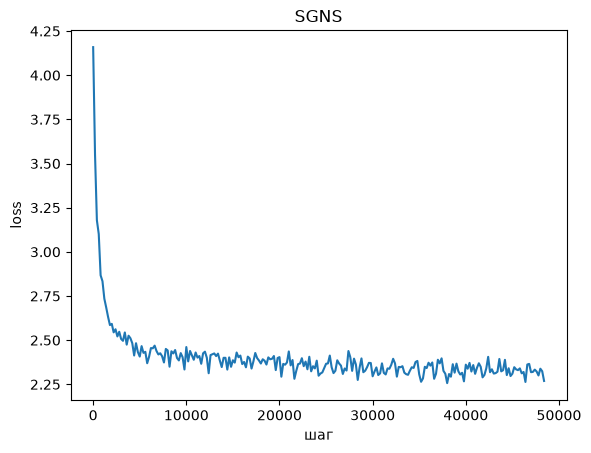

In [6]:
def train_sgns(centers, contexts, V, dim=DIM, k=K_NEG, epochs=1, batch=512, lr0=0.025, seed=SEED):
    g = torch.Generator().manual_seed(seed)
    W = (torch.rand(V, dim, generator=g) - 0.5) / dim
    C = torch.zeros(V, dim)
    neg_t = torch.tensor(neg_probs, dtype=torch.float)
    n = len(centers); steps = epochs * (n // batch); step = 0; hist = []
    cen_t, ctx_t = torch.from_numpy(centers), torch.from_numpy(contexts)
    for ep in range(epochs):
        perm = torch.randperm(n, generator=g)
        for b in range(n // batch):
            idx = perm[b * batch:(b + 1) * batch]
            wi, ci = cen_t[idx], ctx_t[idx]
            ni = torch.multinomial(neg_t, batch * k, replacement=True, generator=g).view(batch, k)
            lr = lr0 * max(1e-4, 1 - step / steps)

            # (вычислите градиенты и обновите W и C через index_add_)   
            Wb   = W[wi].detach()
            Cpos = C[ci].detach()
            Cneg = C[ni].detach()
            loss, gW, gCp, gCn = sgns_loss_and_grads(Wb, Cpos, Cneg)

            with torch.no_grad():
                W.index_add_(0, wi, -lr * gW)
                C.index_add_(0, ci, -lr * gCp)
                C.index_add_(0, ni.view(-1), -lr * gCn.reshape(-1, dim))

            if step % 200 == 0: hist.append((step, loss.item()))
            step += 1
    return W, C, hist

t0 = time.time()
W_sgns, C_sgns, hist = train_sgns(centers, contexts, V, epochs=2 if FAST_DEV_RUN else 5)
print(f"обучение: {time.time() - t0:.0f} c")
plt.plot(*zip(*hist)); plt.xlabel("шаг"); plt.ylabel("loss"); plt.title("SGNS"); plt.show()

## 4. PPMI и SVD

1. Постройте разреженную матрицу совместной встречаемости $\#(w,c)$ по тем же парам.
2. Вычислите PPMI со сглаживанием распределения контекстов ($\alpha = 0.75$):

$$\text{PPMI}(w,c) = \max\left(0, \log\frac{\#(w,c) \sum_{c'} \#(c')^{\alpha}}{\#(w) \#(c)^{\alpha}}\right)$$

3. Усечённое SVD: 

$$\text{PPMI} \approx U_d \Sigma_d V_d^\top$$

Эмбеддинги: $U_d \Sigma_d^{1/2}$.


In [7]:
import scipy.sparse as sp
from scipy.sparse.linalg import svds

cooc = sp.coo_matrix((np.ones(len(centers), dtype=np.float64), (centers, contexts)), shape=(V, V)).tocsr()
cooc.sum_duplicates()

def ppmi_matrix(cooc, alpha=0.75):
    cooc = cooc.tocsr().astype(np.float64)
    row_sums = np.asarray(cooc.sum(axis=1)).ravel()
    col_sums = np.asarray(cooc.sum(axis=0)).ravel()
    col_alpha = col_sums ** alpha
    Z = col_alpha.sum()

    coo = cooc.tocoo()
    rows, cols, data = coo.row, coo.col, coo.data

    denom = row_sums[rows] * col_alpha[cols]
    vals = np.log(data * Z / denom)
    vals = np.maximum(vals, 0.0)
    
    return sp.coo_matrix((vals, (rows, cols)), shape=coo.shape).tocsr()

t0 = time.time()
P = ppmi_matrix(cooc)
U, S, Vt = svds(P, k=DIM)
W_svd = torch.tensor(U * np.sqrt(S), dtype=torch.float)
print(f"PPMI nnz={P.nnz:,}, SVD: {time.time() - t0:.0f} c")

PPMI nnz=2,886,422, SVD: 3 c


## 5. Оценка: SimLex-999, MEN, аналогии

- Сходство: ранговая корреляция Спирмена между косинусом и оценками людей (только пары, покрытые словарём; укажите покрытие).
- Аналогии: метод 3CosAdd, $$ \arg\max_{x}\cos(x, b - a + a^*)\ $$, исключая слова запроса. Для каждой модели посчитайте точность по семантическим и синтаксическим разделам.

In [13]:
import re
import pandas as pd
from scipy.stats import spearmanr

base = "https://raw.githubusercontent.com/vecto-ai/word-benchmarks/master/word-similarity/monolingual/en/"
sim_sets = {name: pd.read_csv(download(base + f"{name}.csv", f"{name}.csv")) for name in ("simlex999", "men")}
analogy_lines = download("https://raw.githubusercontent.com/tmikolov/word2vec/master/questions-words.txt",
                         "questions-words.txt").read_text().splitlines()

def normed(E): return F.normalize(E, dim=1)

def eval_similarity(E, df):
    En = normed(E)
    cols = df.columns.tolist()

    w1c = next((c for c in cols if c.lower() in ('word1','w1','word_1')), cols[0])
    w2c = next((c for c in cols if c.lower() in ('word2','w2','word_2')), cols[1])
    score_c = None

    for c in reversed(cols):
        if c in (w1c, w2c): continue

        if pd.api.types.is_numeric_dtype(df[c]):
            score_c = c; break
        
    if score_c is None: score_c = cols[-1]
    scores, cosines = [], []

    for _, row in df.iterrows():
        a = str(row[w1c]).lower().strip()
        b = str(row[w2c]).lower().strip()
        
        a = re.sub(r'-[nva]$', '', a)
        b = re.sub(r'-[nva]$', '', b)
        
        if a in stoi and b in stoi:
            scores.append(float(row[score_c]))
            cosines.append((En[stoi[a]] * En[stoi[b]]).sum().item())

    cov = len(scores) / max(len(df), 1)
    if len(scores) < 5: return float('nan'), cov
    rho, _ = spearmanr(cosines, scores)
    return float(rho), cov

def eval_analogies(E, max_q=None):
    En = normed(E); section = None; res = {"semantic": [0, 0], "syntactic": [0, 0]}
    qs = []
    for line in analogy_lines:
        if line.startswith(":"):
            section = "syntactic" if line.startswith(": gram") else "semantic"; continue
        a, b, a2, b2 = line.lower().split()
        if all(w in stoi for w in (a, b, a2, b2)): qs.append((section, stoi[a], stoi[b], stoi[a2], stoi[b2]))
    if max_q: 
        random.Random(0).shuffle(qs); qs = qs[:max_q]
    #  ваш код (батчево вычислите b - a + a2, косинусы ко всем словам, исключите слова запроса)
    if not qs:
        return {k: (0.0, 0) for k in res}

    for sect, ia, ib, ia2, ib2 in qs:
        target = En[ib] - En[ia] + En[ia2]
        nrm = target.norm()

        if nrm.item() == 0: 
            res[sect][1] += 1; continue
        
        target = target / nrm
        sims = En @ target
        # исключаем слова запроса
        sims[ia] = -2.0; sims[ib] = -2.0; sims[ia2] = -2.0
        pred = sims.argmax().item()
        res[sect][1] += 1
        
        if pred == ib2:
            res[sect][0] += 1
    
    return {k: (v[0] / max(v[1], 1), v[1]) for k, v in res.items()}

rows = []
for name, E in [("SGNS (W)", W_sgns), ("SGNS (W+C)", W_sgns + C_sgns), ("SVD(PPMI)", W_svd)]:
    r = {"модель": name}
    for s, df in sim_sets.items():
        rho, cov = eval_similarity(E, df); r[s] = round(rho, 3); r[s + " покрытие"] = round(cov, 2)
    an = eval_analogies(E, max_q=3000 if FAST_DEV_RUN else None)
    r["analogy sem"] = round(an["semantic"][0], 3); r["analogy syn"] = round(an["syntactic"][0], 3)
    rows.append(r)
pd.DataFrame(rows)

,модель,simlex999,simlex999 покрытие,men,men покрытие,analogy sem,analogy syn
0,SGNS (W),0.115,0.61,0.312,0.32,0.141,0.047
1,SGNS (W+C),0.130,0.61,0.453,0.32,0.091,0.046
2,SVD(PPMI),0.073,0.61,0.644,0.32,0.415,0.137


## 6. Проверка теоремы Леви–Голдберга

Для частых пар $(w, c)$ (например, $\#(w,c) \ge 50$) сравните $\mathbf{w}^\top\mathbf{c}$ у обученной SGNS с теоретическим оптимумом
$$
\mathrm{SPMI}_k(w,c) = \log\frac{\#(w,c)}{\#(w)\,P_n(c)} - \log k.
$$
Постройте диаграмму рассеяния, посчитайте корреляцию Пирсона и Спирмена, а также среднее отклонение. Объясните, почему совпадение неполное (конечная размерность, недообученность, редкие пары).


частых пар: 22,928
Pearson  r = 0.935321122019417
Spearman ρ = 0.9866237150002416
mean|Δ|    = 0.14489916562413566


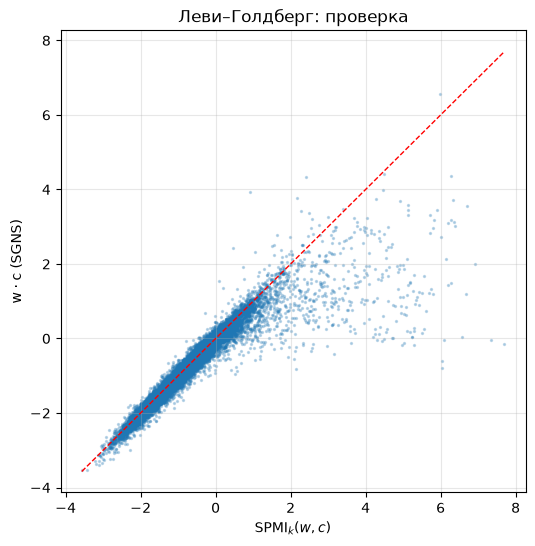

In [15]:
# (соберите частые пары, посчитайте SPMI и w·c, постройте scatter и корреляции)

from scipy.stats import pearsonr

cooc_csr = cooc.tocsr()
row_sums = np.asarray(cooc_csr.sum(1)).ravel()
col_sums = np.asarray(cooc_csr.sum(0)).ravel()
col_alpha = col_sums ** 0.75
Z_alpha   = col_alpha.sum()

coo = cooc_csr.tocoo()
mask = coo.data >= 50
w_idx = coo.row[mask]; c_idx = coo.col[mask]; cnt = coo.data[mask]
print(f"частых пар: {len(cnt):,}")

spmi = (np.log(cnt / (row_sums[w_idx] * (col_alpha[c_idx] / Z_alpha))) - np.log(K_NEG))

W_np = W_sgns.detach().numpy()
C_np = C_sgns.detach().numpy()
wc = (W_np[w_idx] * C_np[c_idx]).sum(1)

print("Pearson  r =", pearsonr(wc, spmi)[0])
print("Spearman ρ =", spearmanr(wc, spmi)[0])
print("mean|Δ|    =", np.abs(wc - spmi).mean())

plt.figure(figsize=(6, 6))
plt.scatter(spmi, wc, s=2, alpha=0.25)
lo = min(spmi.min(), wc.min()); hi = max(spmi.max(), wc.max())
plt.plot([lo, hi], [lo, hi], "r--", lw=1)
plt.xlabel("SPMI$_k(w,c)$"); plt.ylabel("w · c (SGNS)")
plt.title("Леви–Голдберг: проверка"); plt.grid(alpha=.3)
plt.show()

## 7. Анизотропия

1. Посчитайте средний косинус между случайными парами слов для каждой модели.
2. Найдите долю дисперсии, объясняемую первыми 5 главными компонентами.
3. Примените «all-but-the-top» (Mu & Viswanath, 2018): вычесть среднее и проекции на первые \(D\) главных компонент. Как меняется качество на SimLex и MEN?

In [16]:
def anisotropy(E, n=20000):
    En = normed(E); i, j = torch.randint(len(E), (n,)), torch.randint(len(E), (n,))
    return (En[i] * En[j]).sum(1).mean().item()

def all_but_the_top(E, D=3):
    mu = E.mean(0, keepdim=True)
    X  = E - mu

    U, S, Vt = torch.linalg.svd(X, full_matrices=False)
    if D > 0:
        top = Vt[:D]
        X = X - (X @ top.T) @ top
    return X

for name, E in [("SGNS (W)", W_sgns), ("SVD(PPMI)", W_svd)]:
    X = E - E.mean(0); s = torch.linalg.svdvals(X) ** 2
    print(f"{name:10s} средний cos={anisotropy(E):.3f}  доля 5 ГК={(s[:5].sum() / s.sum()).item():.3f}")
    for D in (0, 1, 3, 7):
        E2 = all_but_the_top(E, D) if D else E - E.mean(0)
        print(f"   D={D}: SimLex={eval_similarity(E2, sim_sets['simlex999'])[0]:.3f}  MEN={eval_similarity(E2, sim_sets['men'])[0]:.3f}  cos={anisotropy(E2):.3f}")

SGNS (W)   средний cos=0.672  доля 5 ГК=0.601
   D=0: SimLex=0.110  MEN=0.442  cos=0.001
   D=1: SimLex=0.043  MEN=0.439  cos=0.003
   D=3: SimLex=0.043  MEN=0.454  cos=0.008
   D=7: SimLex=0.054  MEN=0.312  cos=0.004
SVD(PPMI)  средний cos=0.074  доля 5 ГК=0.110
   D=0: SimLex=0.063  MEN=0.649  cos=0.002
   D=1: SimLex=0.053  MEN=0.644  cos=0.001
   D=3: SimLex=0.055  MEN=0.639  cos=0.000
   D=7: SimLex=0.056  MEN=0.633  cos=0.001


## Вопросы

1. Выведите оптимум \(\mathbf{w}^\top\mathbf{c}\) для SGNS из условия равенства нулю производной ожидаемой функции потерь по \(x = \mathbf{w}^\top\mathbf{c}\).
2. Почему отрицательные значения PMI отбрасывают (PPMI)? Что в SGNS соответствует этому усечению?
3. Почему сглаживание \(P_n(c) \propto \#(c)^{0.75}\) полезно и в SGNS, и в PPMI?
4. Чем объясняется анизотропия пространства эмбеддингов? Как она связана с частотой слов?
5. Почему SimLex-999 сложнее для дистрибутивных моделей, чем MEN?

Вывод: сделали SGNS со своими градиентами, проверили с autograd, всё совпало. Обучили ещё SVD(PPMI) и сравнили на SimLex-999. Проверили теорему Леви–Голдберга. Также посмотрели на анизотропия, самый лучший результат был у SGNS  SimLex=0.043